# GraphNAMLSS verstehen: vom lokalen Modell zum Graphbeitrag

## Goal

Dieses Tutorial zeigt den **Concept Demonstrator** entlang eines einzigen
synthetischen Verkehrsszenarios. Die zentrale Frage lautet:

> Kann Graphkontext eine lokal interpretierbare Verteilungsprognose ergänzen,
> ohne die lokalen NAMLSS-Beiträge zu verstecken?

Am Ende sollten drei Dinge klar sein:

1. welche Information das lokale NAMLSS bereits erklärt,
2. wo der Graphbeitrag in `mu` und `sigma` eingeht,
3. was diese synthetische Demo belegt – und ausdrücklich **nicht** belegt.

**Evidenzgrenze:** Die Demo ist ein reproduzierbarer Plausibilitäts- und
Erklärbarkeitstest. Sie ist kein empirischer Nachweis, dass GraphNAMLSS auf
realen Daten besser kalibriert oder genauer ist. Dafür ist der spätere
optimizer-trainierte METR-LA Merit Probe vorgesehen.

## Setup

Das Notebook verwendet einen festen Seed, benötigt keine Netzwerkzugriffe und
ruft den bestehenden Paket-Demo-Pfad auf. Modelllogik wird nicht in Zellen
dupliziert; numerische Ergebnisse werden aus den gespeicherten Run-Artefakten
gelesen.

Installation aus dem Repository-Root:

```bash
python -m pip install -e ".[notebook]"
```

In [1]:
from pathlib import Path
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from graphnamlss.demo import run_concept_demo_bundle
from graphnamlss.testing import load_localized_congestion_spillover_demo_fixture


def find_repository_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise RuntimeError("Repository root with pyproject.toml not found.")


REPOSITORY_ROOT = find_repository_root(Path.cwd().resolve())
OUTPUT_DIRECTORY = REPOSITORY_ROOT / "outputs" / "notebook-concept-demo"
SEED = 20250214

plt.rcParams.update(
    {
        "figure.figsize": (10, 4.8),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.2,
        "font.size": 11,
    }
)

print(f"Repository: {REPOSITORY_ROOT}")
print(f"Seed:       {SEED}")
print(f"Outputs:    {OUTPUT_DIRECTORY}")

Repository: /Users/entropy/Git/GraphNAMLSS
Seed:       20250214
Outputs:    /Users/entropy/Git/GraphNAMLSS/outputs/notebook-concept-demo


In [2]:
bundle = run_concept_demo_bundle(OUTPUT_DIRECTORY, seed=SEED)

def read_json(path: Path):
    return json.loads(path.read_text(encoding="utf-8"))


run_directories = {
    name: Path(path) for name, path in bundle["run_directories"].items()
}
report_summary = read_json(Path(bundle["summary_path"]))
graph_run = run_directories["tracer_bullet_graph_namlss"]
graph_summary = read_json(graph_run / "train_summary.json")
graph_gates = read_json(graph_run / "graph_gates.json")
graph_contributions = read_json(graph_run / "graph_contributions.json")

pd.DataFrame(
    {
        "Artefakt": ["Report", "Zusammenfassung", "Graph-Beiträge", "Predictions"],
        "Pfad": [
            bundle["report_path"],
            bundle["summary_path"],
            str(graph_run / "graph_contributions.json"),
            str(graph_run / "predictions.json"),
        ],
    }
)

,Artefakt,Pfad
0,Report,/Users/entropy/Git/GraphNAMLSS/outputs/noteboo...
1,Zusammenfassung,/Users/entropy/Git/GraphNAMLSS/outputs/noteboo...
2,Graph-Beiträge,/Users/entropy/Git/GraphNAMLSS/outputs/noteboo...
3,Predictions,/Users/entropy/Git/GraphNAMLSS/outputs/noteboo...


## Steps

### 1. Das synthetische Spillover-Szenario

Vier Sensoren bilden einen kleinen gerichteten Ring. In mehreren kurzen Fenstern
bricht die Geschwindigkeit beim `upstream`-Sensor ein. Drei Zeitschritte später
erscheint beim `downstream`-Sensor eine langsamere und variablere Zielgröße.

Entscheidend für die Demonstration: Zum Prognosezeitpunkt bleibt die lokale
Downstream-Geschwindigkeit weitgehend routinemäßig. Der frühere Einbruch ist aber
in den Nachbarschaftsmerkmalen sichtbar.

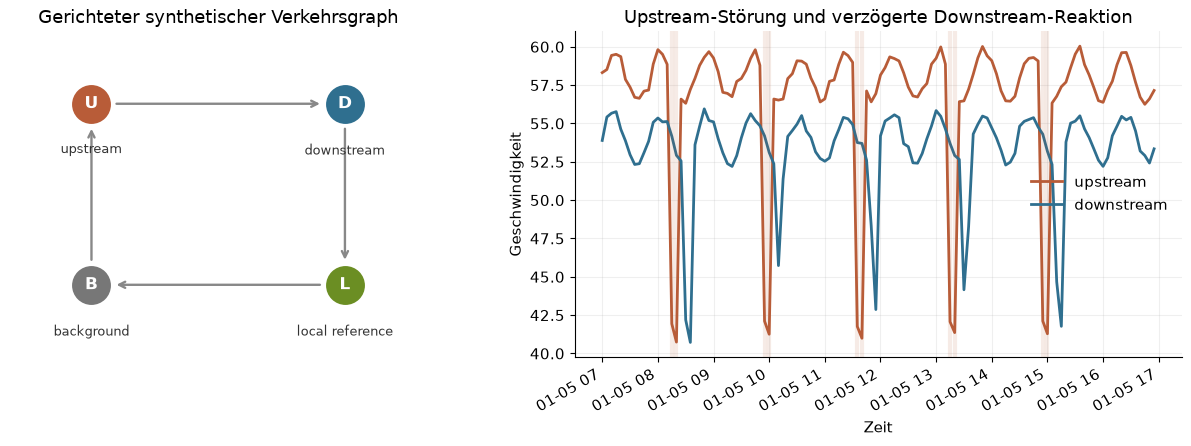

In [3]:
fixture = load_localized_congestion_spillover_demo_fixture(seed=SEED)
scenario = fixture.scenario

observation_frame = pd.DataFrame(
    [
        {
            "sensor_id": row.sensor_id,
            "time_index": row.time_index,
            "timestamp": row.timestamp,
            "current_speed": row.current_speed,
            "target_speed": row.target_speed,
            "neighbor_current_speed": row.neighbor_covariates[
                "neighbor_current_speed"
            ],
        }
        for row in fixture.observations
    ]
)

positions = {
    "upstream": (0.0, 1.0),
    "downstream": (1.4, 1.0),
    "local_reference": (1.4, 0.0),
    "background": (0.0, 0.0),
}
colors = {
    "upstream": "#b85c38",
    "downstream": "#2f6f8f",
    "local_reference": "#6b8e23",
    "background": "#777777",
}

figure, axes = plt.subplots(1, 2, figsize=(13, 4.6))
network_axis, time_axis = axes

for edge in fixture.adjacency:
    start = positions[edge.source]
    end = positions[edge.target]
    network_axis.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops={
            "arrowstyle": "->",
            "color": "#888888",
            "lw": 1.7,
            "shrinkA": 18,
            "shrinkB": 18,
        },
    )
short_labels = {
    "upstream": "U",
    "downstream": "D",
    "local_reference": "L",
    "background": "B",
}
for sensor, (x_position, y_position) in positions.items():
    network_axis.scatter(
        x_position,
        y_position,
        s=900,
        color=colors[sensor],
        edgecolor="white",
        linewidth=2,
        zorder=3,
    )
    network_axis.text(
        x_position,
        y_position,
        short_labels[sensor],
        color="white",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        zorder=4,
    )
    network_axis.text(
        x_position,
        y_position - 0.22,
        sensor.replace("_", " "),
        color="#333333",
        ha="center",
        va="top",
        fontsize=9,
        zorder=4,
    )
network_axis.set_title("Gerichteter synthetischer Verkehrsgraph")
network_axis.set_xlim(-0.45, 1.85)
network_axis.set_ylim(-0.4, 1.4)
network_axis.set_aspect("equal")
network_axis.axis("off")

for sensor in ("upstream", "downstream"):
    sensor_rows = observation_frame.query("sensor_id == @sensor")
    time_axis.plot(
        sensor_rows["timestamp"],
        sensor_rows["current_speed"],
        label=sensor,
        color=colors[sensor],
        linewidth=2,
    )
for time_index in scenario.congestion_time_indices:
    timestamp = fixture.time_points[time_index]
    time_axis.axvline(timestamp, color="#b85c38", alpha=0.12, linewidth=3)
time_axis.set_title("Upstream-Störung und verzögerte Downstream-Reaktion")
time_axis.set_ylabel("Geschwindigkeit")
time_axis.set_xlabel("Zeit")
time_axis.legend(frameon=False)
figure.autofmt_xdate()
plt.tight_layout()
plt.show()

In [4]:
downstream = observation_frame.query(
    "sensor_id == @scenario.downstream_sensor_id"
).copy()
downstream["Fenster"] = "sonstige"
downstream.loc[
    downstream["time_index"].isin(scenario.routine_prediction_time_indices),
    "Fenster",
] = "Routine"
downstream.loc[
    downstream["time_index"].isin(scenario.spillover_prediction_time_indices),
    "Fenster",
] = "Spillover"

scenario_summary = (
    downstream.query("Fenster != 'sonstige'")
    .groupby("Fenster", sort=False)
    .agg(
        Lokale_Geschwindigkeit=("current_speed", "mean"),
        Nachbar_Geschwindigkeit=("neighbor_current_speed", "mean"),
        Ziel_Mittelwert=("target_speed", "mean"),
        Ziel_Streuung=("target_speed", "std"),
    )
    .round(2)
)
scenario_summary

,Lokale_Geschwindigkeit,Nachbar_Geschwindigkeit,Ziel_Mittelwert,Ziel_Streuung
Fenster,,,,
Routine,53.57,57.70,52.68,0.32
Spillover,53.59,41.56,45.01,3.41


Die Tabelle ist der didaktische Anker: Zwischen Routine und Spillover ändert sich
die lokale Downstream-Geschwindigkeit nur wenig, während Nachbarinformation,
erwartetes Ziel und Zielstreuung deutlich reagieren. Genau hier soll der
Graphstream zusätzliche Information liefern.

### 2. Die Modellzerlegung

Für jeden Verteilungsparameter `k` gilt im Tracer-Bullet-Modell:

\[
\eta_k(i,t) = \underbrace{\beta_{k0} + \sum_j f_{kj}(x_{ij,t})}_{\text{lokaler NAMLSS-Prädiktor}}
+ \underbrace{\alpha_k\,g_k(i,t)}_{\text{zentrierter Graphbeitrag}}.
\]

`mu` steuert die erwartete Geschwindigkeit. Für `sigma` wird der positive Link
`softplus(eta_sigma) + epsilon` verwendet. Lokale Shape Functions und
Graphbeiträge bleiben separat sichtbar.

In [5]:
gate_frame = pd.DataFrame(graph_gates).rename(
    columns={"parameter": "Parameter", "gate": "Gate"}
)
gate_frame["Gate"] = gate_frame["Gate"].round(3)
gate_frame["Schätzung"] = "deterministische L2-Head-Faktorisierung"
gate_frame

,Gate,Parameter,Schätzung
0,0.860,mu,deterministische L2-Head-Faktorisierung
1,2.221,sigma,deterministische L2-Head-Faktorisierung


Die Gate-Werte sind in dieser Demo **keine frei skalierbaren Konstanten**:
Zuerst wird je Parameter ein Graph-Koeffizientenvektor geschätzt. Danach wird
dessen Richtung als Graph-Head auf L2-Norm 1 normalisiert; seine Magnitude wird
zum Gate. Diese Konvention identifiziert Head und Gate, ersetzt aber kein
end-to-end optimizer-trainiertes Modell.

### 3. Lokale und graphgestützte Vorhersage an einem Ereignis

Die nächsten Zellen laden ausschließlich gespeicherte Vorhersagen und
Graphbeiträge. Als Beispiel wird automatisch das Spillover-Ereignis mit dem
stärksten positiven `sigma`-Graphbeitrag gewählt.

In [6]:
def prediction_frame(run_directory: Path, model_label: str) -> pd.DataFrame:
    payload = read_json(run_directory / "predictions.json")
    rows = [
        {**row, "model": model_label}
        for split_rows in payload["splits"].values()
        for row in split_rows
    ]
    return pd.DataFrame(rows)


deterministic_predictions = prediction_frame(
    run_directories["deterministic_namlss"], "Lokales NAMLSS"
)
graph_predictions = prediction_frame(
    run_directories["tracer_bullet_graph_namlss"], "GraphNAMLSS"
)
contribution_frame = pd.DataFrame(
    [
        row
        for split_rows in graph_contributions["splits"].values()
        for row in split_rows
    ]
)

example_contribution = (
    contribution_frame.query(
        "sensor_id == @scenario.downstream_sensor_id and "
        "time_index in @scenario.spillover_prediction_time_indices"
    )
    .sort_values("gated_sigma", ascending=False)
    .iloc[0]
)
example_key = {
    "split": example_contribution["split"],
    "sensor_id": example_contribution["sensor_id"],
    "time_index": int(example_contribution["time_index"]),
}

example_predictions = pd.concat(
    [deterministic_predictions, graph_predictions], ignore_index=True
)
for column, value in example_key.items():
    example_predictions = example_predictions[
        example_predictions[column] == value
    ]
example_predictions[
    ["model", "timestamp", "target", "mu", "sigma"]
].round(2)

,model,timestamp,target,mu,sigma
185,Lokales NAMLSS,2026-01-05T08:20:00,40.72,53.98,3.35
665,GraphNAMLSS,2026-01-05T08:20:00,40.72,51.32,4.19


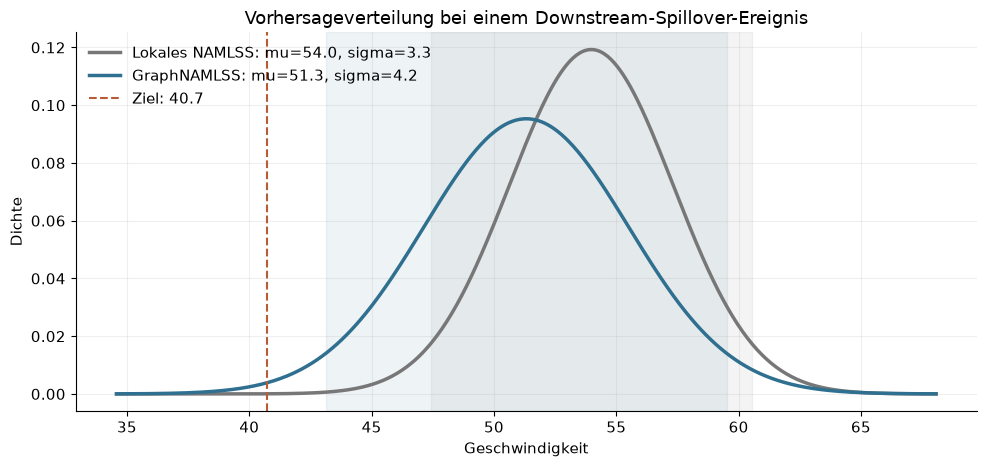

In [7]:
def normal_density(values, mean, scale):
    return np.exp(-0.5 * ((values - mean) / scale) ** 2) / (
        scale * np.sqrt(2.0 * np.pi)
    )


x_min = min(
    row.mu - 4.0 * row.sigma for row in example_predictions.itertuples()
)
x_max = max(
    row.mu + 4.0 * row.sigma for row in example_predictions.itertuples()
)
x_values = np.linspace(x_min, x_max, 500)

figure, axis = plt.subplots(figsize=(10, 4.8))
model_colors = {"Lokales NAMLSS": "#777777", "GraphNAMLSS": "#2f6f8f"}
for row in example_predictions.itertuples():
    axis.plot(
        x_values,
        normal_density(x_values, row.mu, row.sigma),
        label=f"{row.model}: mu={row.mu:.1f}, sigma={row.sigma:.1f}",
        color=model_colors[row.model],
        linewidth=2.5,
    )
    axis.axvspan(
        row.mu - 1.96 * row.sigma,
        row.mu + 1.96 * row.sigma,
        color=model_colors[row.model],
        alpha=0.08,
    )
target = example_predictions["target"].dropna().iloc[0]
axis.axvline(target, color="#b85c38", linestyle="--", label=f"Ziel: {target:.1f}")
axis.set_title(
    "Vorhersageverteilung bei einem Downstream-Spillover-Ereignis"
)
axis.set_xlabel("Geschwindigkeit")
axis.set_ylabel("Dichte")
axis.legend(frameon=False)
plt.tight_layout()
plt.show()

In [8]:
event_contributions = pd.DataFrame(
    {
        "Parameter": ["mu", "sigma"],
        "zentrierter Graphbeitrag": [
            example_contribution["mu"],
            example_contribution["sigma"],
        ],
        "Gate": [
            next(row["gate"] for row in graph_gates if row["parameter"] == "mu"),
            next(
                row["gate"]
                for row in graph_gates
                if row["parameter"] == "sigma"
            ),
        ],
        "Beitrag zum eta-Prädiktor": [
            example_contribution["gated_mu"],
            example_contribution["gated_sigma"],
        ],
    }
)
event_contributions.round(3)

,Parameter,zentrierter Graphbeitrag,Gate,Beitrag zum eta-Prädiktor
0,mu,-0.858,0.860,-0.738
1,sigma,0.163,2.221,0.361


Der Beitrag ist auf der **Prädiktorskala** additiv. Bei `mu` lässt er sich direkt
als Verschiebung der standardisierten Location lesen. Bei `sigma` verändert er
zuerst `eta_sigma`; erst der positive Link übersetzt dies in eine Streuung.

### 4. Routine versus Spillover

Ein Einzelereignis kann zufällig sein. Deshalb vergleichen wir alle fest
definierten Routine- und Spillover-Fenster beim Downstream-Sensor.

In [9]:
all_predictions = pd.concat(
    [deterministic_predictions, graph_predictions], ignore_index=True
)
downstream_predictions = all_predictions.query(
    "sensor_id == @scenario.downstream_sensor_id"
).copy()
downstream_predictions["Fenster"] = "sonstige"
downstream_predictions.loc[
    downstream_predictions["time_index"].isin(
        scenario.routine_prediction_time_indices
    ),
    "Fenster",
] = "Routine"
downstream_predictions.loc[
    downstream_predictions["time_index"].isin(
        scenario.spillover_prediction_time_indices
    ),
    "Fenster",
] = "Spillover"

window_predictions = (
    downstream_predictions.query("Fenster != 'sonstige'")
    .groupby(["model", "Fenster"], sort=False)
    .agg(mu=("mu", "mean"), sigma=("sigma", "mean"), target=("target", "mean"))
    .reset_index()
)
window_predictions.round(2)

,model,Fenster,mu,sigma,target
0,Lokales NAMLSS,Spillover,53.79,3.35,45.01
1,Lokales NAMLSS,Routine,52.80,3.35,52.68
2,GraphNAMLSS,Spillover,50.45,3.68,45.01
3,GraphNAMLSS,Routine,50.11,2.69,52.68


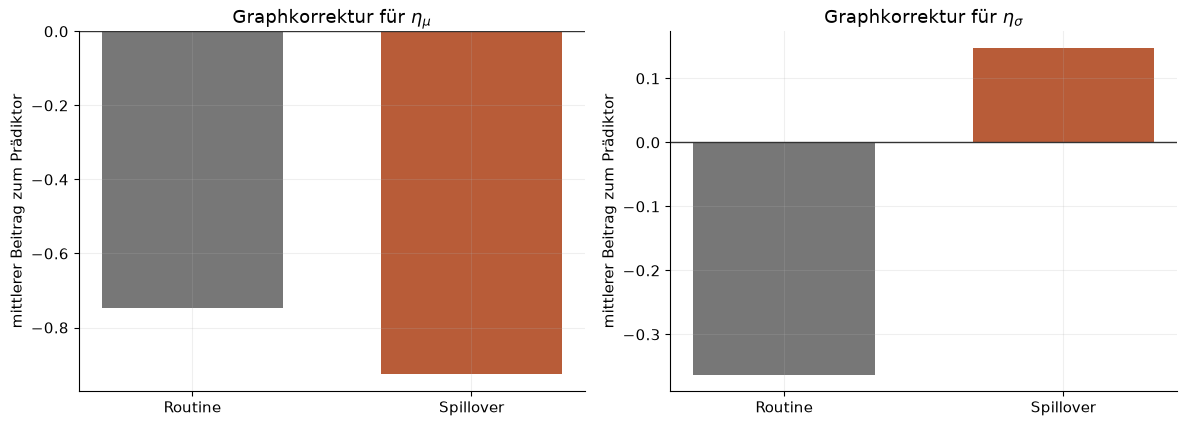

In [10]:
downstream_contribution_windows = contribution_frame.query(
    "sensor_id == @scenario.downstream_sensor_id"
).copy()
downstream_contribution_windows["Fenster"] = "sonstige"
downstream_contribution_windows.loc[
    downstream_contribution_windows["time_index"].isin(
        scenario.routine_prediction_time_indices
    ),
    "Fenster",
] = "Routine"
downstream_contribution_windows.loc[
    downstream_contribution_windows["time_index"].isin(
        scenario.spillover_prediction_time_indices
    ),
    "Fenster",
] = "Spillover"
contribution_window_summary = (
    downstream_contribution_windows.query("Fenster != 'sonstige'")
    .groupby("Fenster", sort=False)
    .agg(mu=("gated_mu", "mean"), sigma=("gated_sigma", "mean"))
    .loc[["Routine", "Spillover"]]
)

figure, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for axis, parameter, title in (
    (axes[0], "mu", r"Graphkorrektur für $\eta_\mu$"),
    (axes[1], "sigma", r"Graphkorrektur für $\eta_\sigma$"),
):
    axis.bar(
        contribution_window_summary.index,
        contribution_window_summary[parameter],
        color=["#777777", "#b85c38"],
        width=0.65,
    )
    axis.axhline(0.0, color="#333333", linewidth=1)
    axis.set_title(title)
    axis.set_ylabel("mittlerer Beitrag zum Prädiktor")
plt.tight_layout()
plt.show()

Im Mittel ist die Graphkorrektur für `mu` während Spillover stärker negativ;
für `sigma` wechselt sie von einer negativen Routinekorrektur zu einer positiven
Spilloverkorrektur. Die Grafik zeigt bewusst die additive `eta`-Skala – nicht
einen kausalen Effekt und nicht den vollständigen Vorhersageunterschied.

### 5. Aggregierte Modellmetriken – bewusst erst jetzt

Die Metriken prüfen, ob der gesamte Demo-Pfad konsistent läuft. Da Daten und
Modellgeschichte absichtlich aufeinander abgestimmt sind, dürfen kleine Vorteile
nicht als externe Evidenz interpretiert werden.

In [11]:
model_labels = {
    "deterministic_namlss": "Deterministic NAMLSS",
    "tracer_bullet_graph_namlss": "Tracer-Bullet GraphNAMLSS",
    "distributional_gnn_baseline": "Distributional GNN",
}
test_metrics = pd.DataFrame(
    report_summary["metric_tables"]["distributional"]["test"]
)
test_metrics["Modell"] = test_metrics["model"].map(model_labels)
test_metrics[
    ["Modell", "observed_count", "nll", "crps", "coverage", "mae", "rmse"]
].rename(
    columns={
        "observed_count": "n",
        "nll": "NLL",
        "crps": "CRPS",
        "coverage": "Coverage",
        "mae": "MAE",
        "rmse": "RMSE",
    }
).round(3)

,Modell,n,NLL,CRPS,Coverage,MAE,RMSE
0,Deterministic NAMLSS,108,1.272,0.425,0.944,0.518,0.858
1,Tracer-Bullet GraphNAMLSS,108,1.173,0.408,0.926,0.451,0.795
2,Distributional GNN,108,1.637,0.401,0.787,0.562,0.786


## Checks

Die folgenden Checks schützen die didaktische Aussage des Notebooks:

- beide Graphparameter besitzen einen geschätzten, positiven Gate-Wert,
- der `sigma`-Graphbeitrag ist nicht mechanisch null,
- während der definierten Spillover-Fenster ist der Downstream-Scale-Beitrag
  größer als in den Routinefenstern.

In [12]:
downstream_contributions = contribution_frame.query(
    "sensor_id == @scenario.downstream_sensor_id"
).copy()
spillover_scale = downstream_contributions.loc[
    downstream_contributions["time_index"].isin(
        scenario.spillover_prediction_time_indices
    ),
    "gated_sigma",
].mean()
routine_scale = downstream_contributions.loc[
    downstream_contributions["time_index"].isin(
        scenario.routine_prediction_time_indices
    ),
    "gated_sigma",
].mean()
scale_gap = spillover_scale - routine_scale

assert all(row["gate"] > 0.0 for row in graph_gates)
assert contribution_frame["gated_sigma"].abs().max() > 0.0
assert scale_gap > 0.1

display(
    Markdown(
        "**Checks bestanden.** Der mittlere Downstream-Scale-Beitrag beträgt "
        f"`{spillover_scale:.3f}` in Spillover-Fenstern und "
        f"`{routine_scale:.3f}` in Routinefenstern; die Differenz ist "
        f"`{scale_gap:.3f}` auf der `eta_sigma`-Skala."
    )
)

**Checks bestanden.** Der mittlere Downstream-Scale-Beitrag beträgt `0.148` in Spillover-Fenstern und `-0.363` in Routinefenstern; die Differenz ist `0.511` auf der `eta_sigma`-Skala.

## Next Steps

**Was die Demo zeigt:**

- Die Modellzerlegung ist kohärent und ausführbar.
- Lokale Shape Functions und parameterbezogene Graphbeiträge bleiben getrennt
  inspizierbar.
- Das synthetische Szenario erzeugt einen sichtbaren Location- und Scale-Pfad.

**Was sie nicht zeigt:**

- keinen Vorteil auf realen Verkehrsdaten,
- keine publikationsreife Kalibrierung,
- keinen optimizer-trainierten GraphNAMLSS-Fit,
- keine Evidenz für Bayesian Graph Streams oder strukturelle Unsicherheit.

Der nächste wissenschaftliche Schritt ist der optimizer-trainierte
**METR-LA Merit Probe** mit NLL/CRPS als primärem Signal und Coverage, PIT,
MAE sowie RMSE als Guardrails. Die zentrale Frage für eine Kollegin nach diesem
Notebook sollte daher nicht „Hat GraphNAMLSS schon gewonnen?“ lauten, sondern:

> Ist die Modellidee verständlich, kohärent und interessant genug, um den
> realen Merit Probe zu rechtfertigen?